In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pymc as pm
import arviz as az
import ICIW_Plots
from scipy.integrate import odeint
import pytensor as pt
from HSA_Cam_A_006 import (
    Chem,
    bmodel,
    plot_true_data,
    plot_observed_data,
    plot_inference,
    plot_model_trace,
    model_inference,
    theta_true,
    y0_true,
    sigma,
)
import xarray

pt.config.mode = "NUMBA"

WARNING (pytensor.configdefaults): g++ not available, if using conda: `conda install gxx`
WARNING (pytensor.configdefaults): g++ not detected!  PyTensor will be unable to compile C-implementations and will default to Python. Performance may be severely degraded. To remove this warning, set PyTensor flags cxx to an empty string.


In [2]:
plt.style.use("ICIWstyle")

## The base model

In [3]:
times = np.linspace(0, 1 * 60 * 60, 100)

y_true = xarray.DataArray(
    np.zeros((6, len(times), 5)),
    dims=["temperature", "time", "state"],
    coords={
        "temperature": [250, 280, 300, 320, 350, 400],
        "time": times,
        "state": ["n_g_con", "c_Al", "c_Bl", "c_Cl", "c_Dl"],
    },
)
# display(y_true.coords["temperature"])

for i, T in enumerate(y_true.coords["temperature"]):
    theta = (
        theta_true[0],
        T,
        theta_true[2],
        theta_true[3],
        theta_true[4],
        theta_true[5],
        theta_true[6],
    )
    y_true[i, :, :] = odeint(
        Chem.reaction, t=times, y0=y0_true, args=(np.array(theta),)
    )
y_true[:, :, 0] *= 1000  # convert m3 to L H2 used (up to a constant atleast)

# Add noise
t_obs = times[::10]
y_obs = np.random.normal(y_true[4, :, :], sigma)[::10, :]  # downsample and add noise

: 

c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


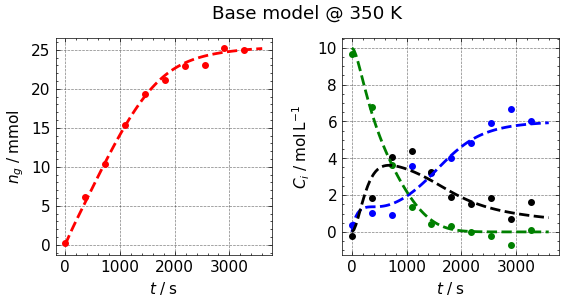

In [5]:
## Plotting the base model
fig = ICIW_Plots.figure(layout="double_column")
axs = ICIW_Plots.make_square_subplots(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    ax_layout=(1, 2),
    h_sep=0.7,
    xlabel=r"$t\;/\;\mathrm{s}$",
    ylabel=[[r"$n_g\;/\;\mathrm{mmol}$", r"$C_i\;/\;\mathrm{mol\,L^{-1}}$"]],
)
plot_true_data(axs, times, y_true[4, :, :])
plot_observed_data(axs, t_obs, y_obs)
plt.suptitle("Base model @ 350 K")
plt.show()

## Sample the prior distribution

In [6]:
model = bmodel(t_obs, 350, y_obs)
with model:
    prior_idata = pm.sample_prior_predictive(samples=1000, random_seed=23489)

Sampling: [A01, A02, EA1, EA2, LH2, kla, sigma]


c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\IPython\core\events.py:82: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  func(*args, **kwargs)
c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


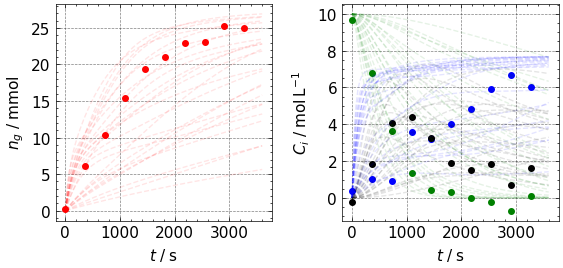

In [7]:
fig = ICIW_Plots.figure(layout="double_column")
axs = ICIW_Plots.make_square_subplots(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    ax_layout=(1, 2),
    h_sep=0.7,
    xlabel=r"$t\;/\;\mathrm{s}$",
    ylabel=[[r"$n_g\;/\;\mathrm{mmol}$", r"$C_i\;/\;\mathrm{mol\,L^{-1}}$"]],
)
plot_observed_data(axs, t_obs, y_obs)
plot_inference(
    axs,
    prior_idata,
    times=times,
    num_samples=25,
    lw=1,
    alpha=0.1,
)

## Sample the posterior given the first profile at 350 K

In [8]:
try:
    posterior_idata = az.from_netcdf("HSA_Cam_A_006_posterior.nc")
    print("Loaded posterior from file.")
except FileNotFoundError:
    vars_list = list(model.values_to_rvs.keys())[:-1]
    with model:
        posterior_idata = pm.sample(
            step=[pm.DEMetropolisZ(vars_list)],
            draws=10000,
            tune=2000,
            # target_accept=0.9,
            random_seed=23489,
            return_inferencedata=True,
            # nuts_sampler="numpyro",
        )
    posterior_idata.to_netcdf("HSA_Cam_A_006_posterior.nc")

c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\pytensor\link\c\cmodule.py:2968: UserWarning: PyTensor could not link to a BLAS installation. Operations that might benefit from BLAS will be severely degraded.
This usually happens when PyTensor is installed via pip. We recommend it be installed via conda/mamba/pixi instead.
Alternatively, you can use an experimental backend such as Numba or JAX that perform their own BLAS optimizations, by setting `pytensor.config.mode == 'NUMBA'` or passing `mode='NUMBA'` when compiling a PyTensor function.
For more options and details see https://pytensor.readthedocs.io/en/latest/troubleshooting.html#how-do-i-configure-test-my-blas-library
  warnings.warn(
Multiprocess sampling (4 chains in 4 jobs)
DEMetropolisZ: [kla, A01, EA1, A02, EA2, sigma]
Could not pickle model, sampling singlethreaded.
Sequential sampling (4 chains in 1 job)
DEMetropolisZ: [kla, A01, EA1, A02, EA2, sigma]


Output()

c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\threadpoolctl.py:1226: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)


Sampling 4 chains for 2_000 tune and 10_000 draw iterations (8_000 + 40_000 draws total) took 95 seconds.
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details
The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


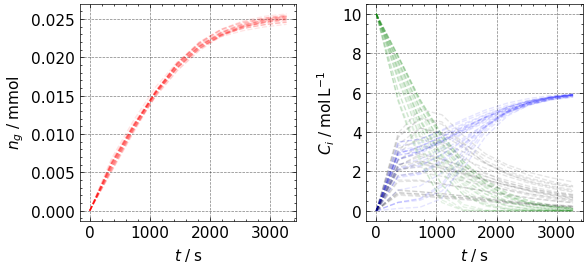

In [65]:
post_data = az.extract(
    posterior_idata,
    group="posterior",
    num_samples=25,
    var_names=["y_hat"],
)
# display(post_data)

fig = ICIW_Plots.figure(layout="double_column")
axs = ICIW_Plots.make_square_subplots(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    ax_layout=(1, 2),
    h_sep=0.7,
    xlabel=r"$t\;/\;\mathrm{s}$",
    ylabel=[[r"$n_g\;/\;\mathrm{mmol}$", r"$C_i\;/\;\mathrm{mol\,L^{-1}}$"]],
)

for i in range(25):
    # print(f"Plotting sample {i+1}/25")
    plot_true_data(
        axs,
        t_obs,
        post_data.values[:, :, i],
        lw=1,
        alpha=0.1,
    )
plt.show()

c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


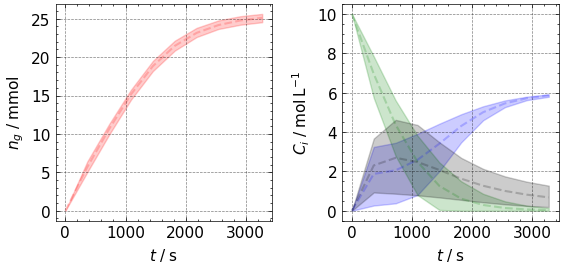

In [66]:
post_data = az.extract(
    posterior_idata,
    group="posterior",
    var_names=["y_hat"],
).copy()
# display(post_data)

post_data[:, 0, :] *= 1000

fig = ICIW_Plots.figure(layout="double_column")
axs = ICIW_Plots.make_square_subplots(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    ax_layout=(1, 2),
    h_sep=0.7,
    xlabel=r"$t\;/\;\mathrm{s}$",
    ylabel=[[r"$n_g\;/\;\mathrm{mmol}$", r"$C_i\;/\;\mathrm{mol\,L^{-1}}$"]],
)

# plot_true_data(axs, times, y_true, lw=2)

plot_true_data(
    axs,
    t_obs,
    post_data.values.mean(axis=2),
    lw=1.5,
    alpha=0.2,
)

axs[0, 0].fill_between(
    t_obs,
    np.percentile(post_data.values, 5, axis=2)[:, 0],
    np.percentile(post_data.values, 95, axis=2)[:, 0],
    color="red",
    alpha=0.2,
    zorder=0,
)

axs[0, 1].fill_between(
    t_obs,
    np.percentile(post_data.values, 5, axis=2)[:, 1],
    np.percentile(post_data.values, 95, axis=2)[:, 1],
    color=["blue"],
    alpha=0.2,
    zorder=0,
)
axs[0, 1].fill_between(
    t_obs,
    np.percentile(post_data.values, 5, axis=2)[:, 2],
    np.percentile(post_data.values, 95, axis=2)[:, 2],
    color=["green"],
    alpha=0.2,
    zorder=0,
)
axs[0, 1].fill_between(
    t_obs,
    np.percentile(post_data.values, 5, axis=2)[:, 3],
    np.percentile(post_data.values, 95, axis=2)[:, 3],
    color=["black"],
    alpha=0.2,
    zorder=0,
)


plt.show()

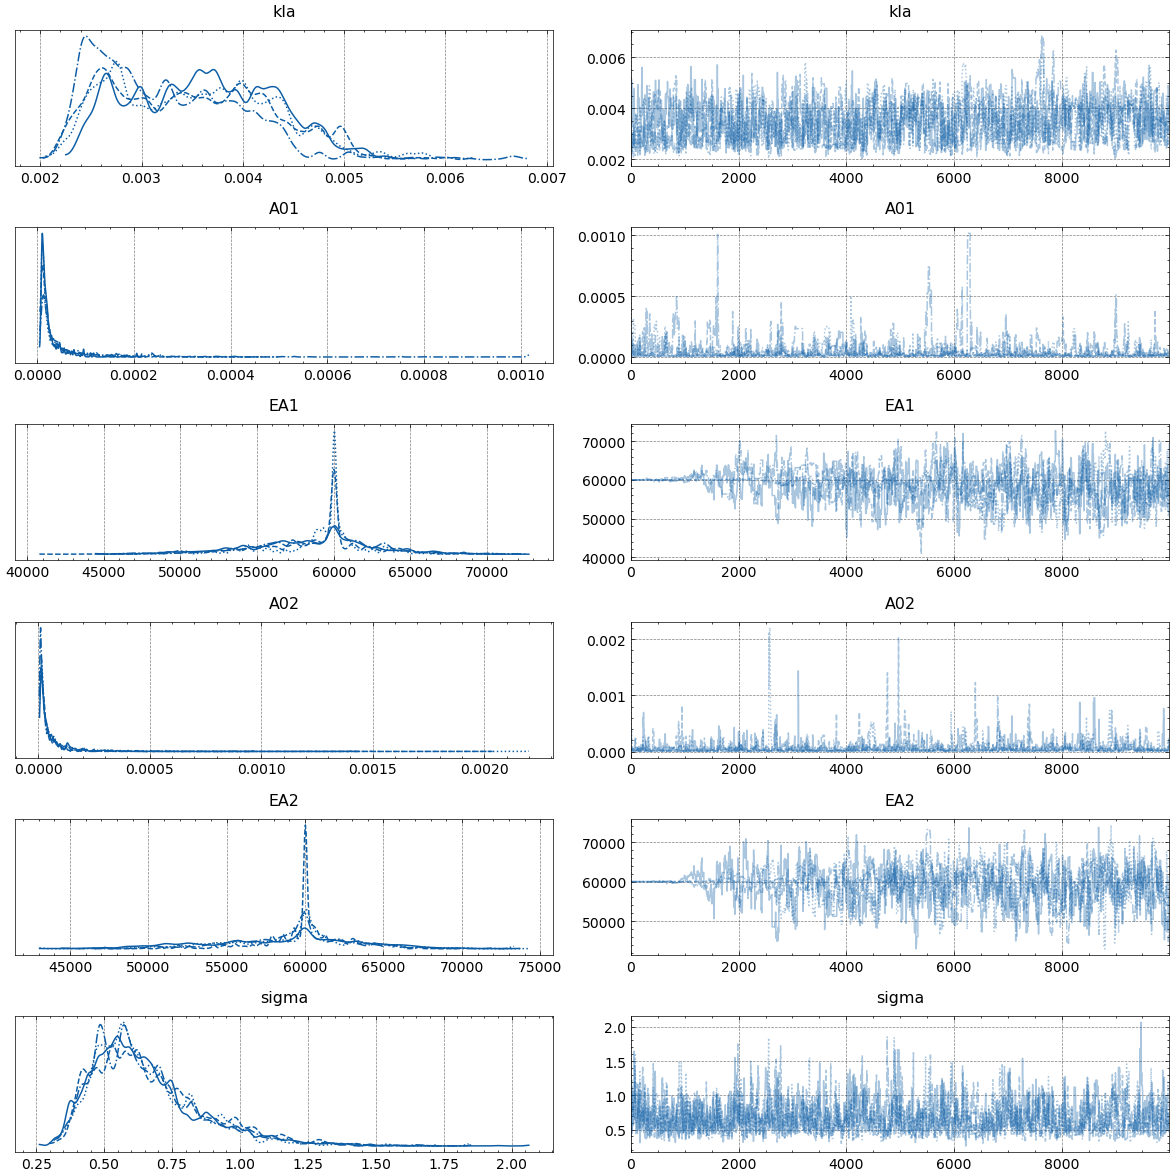

In [67]:
az.plot_trace(
    posterior_idata,
    var_names=[
        "kla",
        "A01",
        "EA1",
        "A02",
        "EA2",
        "sigma",
    ],
)
plt.show()

Text(0.5, 0.98, 'Posterior model @ 350 K')

c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\IPython\core\events.py:82: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  func(*args, **kwargs)
c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


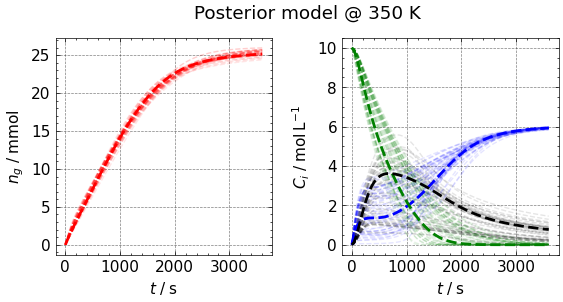

In [68]:
fig = ICIW_Plots.figure(layout="double_column")
axs = ICIW_Plots.make_square_subplots(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    ax_layout=(1, 2),
    h_sep=0.7,
    xlabel=r"$t\;/\;\mathrm{s}$",
    ylabel=[[r"$n_g\;/\;\mathrm{mmol}$", r"$C_i\;/\;\mathrm{mol\,L^{-1}}$"]],
)

plot_inference(
    axs,
    posterior_idata,
    times=times,
    group="posterior",
    num_samples=50,
    theta_indep=(10e5, 350),
    lw=1,
    alpha=0.1,
)
plot_true_data(axs, times, y_true[4, :, :])
plt.suptitle("Posterior model @ 350 K")

Text(0.5, 0.98, 'Posterior model @ 300 K')

c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\IPython\core\events.py:82: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  func(*args, **kwargs)
c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


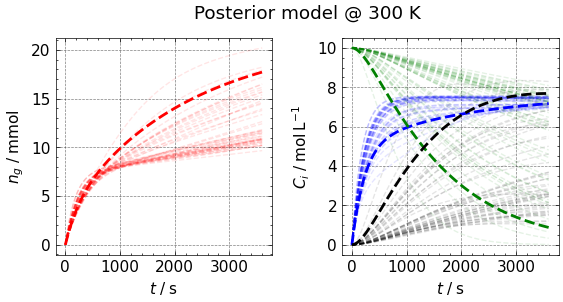

In [69]:
fig = ICIW_Plots.figure(layout="double_column")
axs = ICIW_Plots.make_square_subplots(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    ax_layout=(1, 2),
    h_sep=0.7,
    xlabel=r"$t\;/\;\mathrm{s}$",
    ylabel=[[r"$n_g\;/\;\mathrm{mmol}$", r"$C_i\;/\;\mathrm{mol\,L^{-1}}$"]],
)

plot_inference(
    axs,
    posterior_idata,
    times=times,
    group="posterior",
    num_samples=50,
    theta_indep=(10e5, 300),
    lw=1,
    alpha=0.1,
)
plot_true_data(axs, times, y_true[2, :, :])
plt.suptitle("Posterior model @ 300 K")

### How does the posterior behave given extrapolation?

In [70]:
Ts = np.linspace(280, 400, 50)
y_hatses = []
y_trues = []
for T in Ts:
    y_hats = model_inference(
        posterior_idata,
        y0_true,
        times,
        theta_indep=(10e5, T),
        n_samples=99,
    )
    # print(y_hats.shape)
    y_hatses.append(y_hats)
    y_trues.append(
        odeint(
            Chem.reaction,
            t=times,
            y0=y0_true,
            args=((theta_true[0], T, *theta_true[2:]),),
        )
    )
y_hatses = np.array(y_hatses)
y_trues = np.array(y_trues)

c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\IPython\core\events.py:82: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  func(*args, **kwargs)
c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


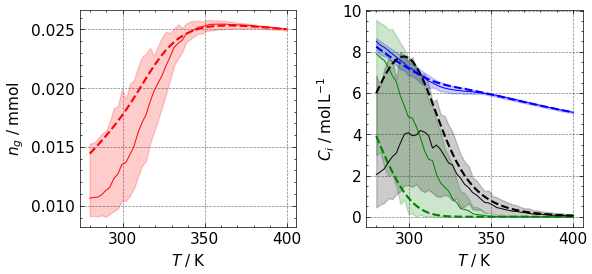

In [71]:
mean_y_hat = y_hatses.mean(axis=1)
CI5 = np.percentile(y_hatses, 5, axis=1)
CI95 = np.percentile(y_hatses, 95, axis=1)

fig = ICIW_Plots.figure(layout="double_column")
axs = ICIW_Plots.make_square_subplots(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    ax_layout=(1, 2),
    h_sep=0.7,
    xlabel=r"$T\;/\;\mathrm{K}$",
    ylabel=[[r"$n_g\;/\;\mathrm{mmol}$", r"$C_i\;/\;\mathrm{mol\,L^{-1}}$"]],
)
axs[0, 0].plot(Ts, mean_y_hat[:, -1, 0], color="red", lw=0.7)
axs[0, 0].plot(Ts, y_trues[:, -1, 0], "--", color="red")
axs[0, 0].fill_between(Ts, CI5[:, -1, 0], CI95[:, -1, 0], color="red", alpha=0.2)
axs[0, 1].plot(Ts, mean_y_hat[:, -1, 1], color="blue", lw=0.7)
axs[0, 1].plot(Ts, y_trues[:, -1, 1], "--", color="blue")
axs[0, 1].fill_between(Ts, CI5[:, -1, 1], CI95[:, -1, 1], color="blue", alpha=0.2)
axs[0, 1].plot(Ts, mean_y_hat[:, -1, 2], color="green", lw=0.7)
axs[0, 1].plot(Ts, y_trues[:, -1, 2], "--", color="green")
axs[0, 1].fill_between(Ts, CI5[:, -1, 2], CI95[:, -1, 2], color="green", alpha=0.2)
axs[0, 1].plot(Ts, mean_y_hat[:, -1, 3], color="black", lw=0.7)
axs[0, 1].plot(Ts, y_trues[:, -1, 3], "--", color="black")
axs[0, 1].fill_between(Ts, CI5[:, -1, 3], CI95[:, -1, 3], color="black", alpha=0.2)

## sample the posterior given the second profile at 280 K

In [72]:
## define the second temperature to investigate
y_obs = np.random.normal(y_true[1, :, :], sigma)[::10, :]  # downsample and add noise
model = bmodel(t_obs, 280, y_obs, prior=posterior_idata)
try:
    posterior_idata = az.from_netcdf("HSA_Cam_A_006_posterior_inf2.nc")
    print("Loaded posterior from file.")
except FileNotFoundError:
    vars_list = list(model.values_to_rvs.keys())[:-1]
    with model:
        posterior_idata = pm.sample(
            step=[pm.DEMetropolisZ(vars_list)],
            draws=10000,
            tune=2000,
            # target_accept=0.9,
            random_seed=23489,
            return_inferencedata=True,
            # nuts_sampler="numpyro",
        )
    posterior_idata.to_netcdf("HSA_Cam_A_006_posterior_inf2.nc")

Loaded posterior from file.


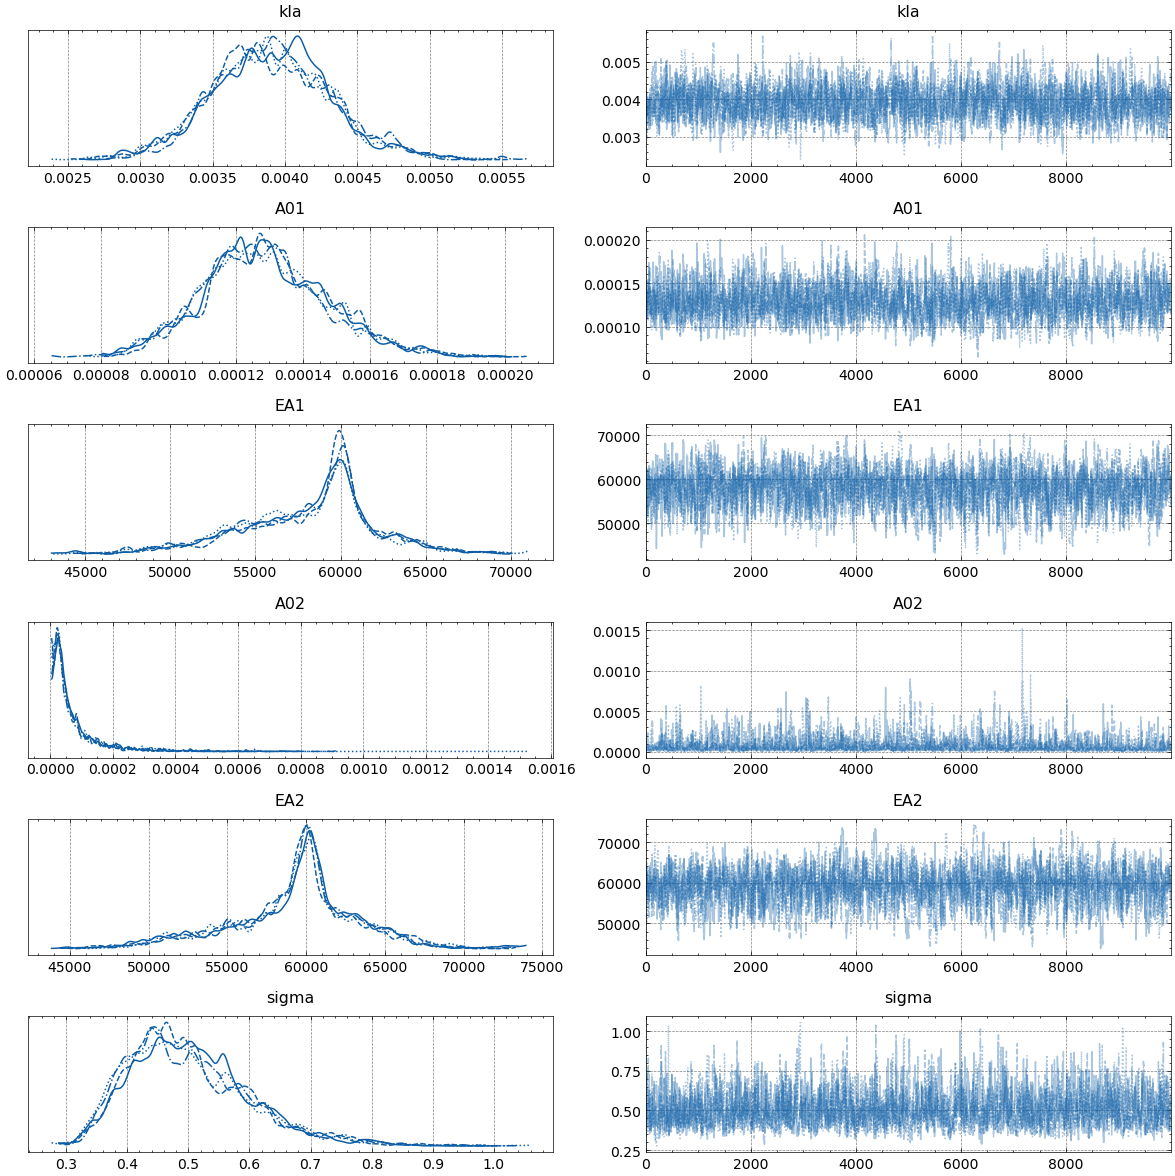

In [73]:
az.plot_trace(
    posterior_idata,
    var_names=[
        "kla",
        "A01",
        "EA1",
        "A02",
        "EA2",
        "sigma",
    ],
)
plt.show()

Text(0.5, 0.98, 'Posterior model @ 280 K')

c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\IPython\core\events.py:82: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  func(*args, **kwargs)
c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


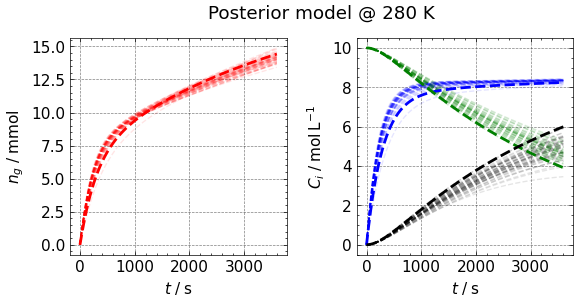

In [74]:
fig = ICIW_Plots.figure(layout="double_column")
axs = ICIW_Plots.make_square_subplots(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    ax_layout=(1, 2),
    h_sep=0.7,
    xlabel=r"$t\;/\;\mathrm{s}$",
    ylabel=[[r"$n_g\;/\;\mathrm{mmol}$", r"$C_i\;/\;\mathrm{mol\,L^{-1}}$"]],
)

plot_inference(
    axs,
    posterior_idata,
    times=times,
    group="posterior",
    num_samples=50,
    theta_indep=(10e5, 280),
    lw=1,
    alpha=0.1,
)
plot_true_data(axs, times, y_true[1, :, :])
plt.suptitle("Posterior model @ 280 K")

Text(0.5, 0.98, 'Posterior model @ 350 K')

c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\IPython\core\events.py:82: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  func(*args, **kwargs)
c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


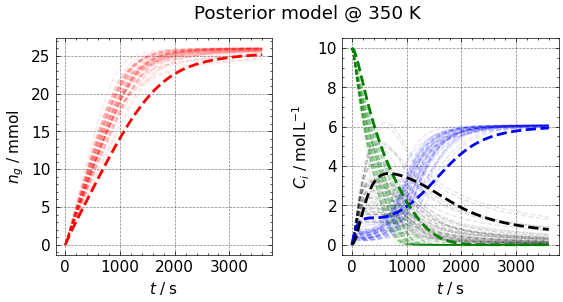

In [75]:
fig = ICIW_Plots.figure(layout="double_column")
axs = ICIW_Plots.make_square_subplots(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    ax_layout=(1, 2),
    h_sep=0.7,
    xlabel=r"$t\;/\;\mathrm{s}$",
    ylabel=[[r"$n_g\;/\;\mathrm{mmol}$", r"$C_i\;/\;\mathrm{mol\,L^{-1}}$"]],
)

plot_inference(
    axs,
    posterior_idata,
    times=times,
    group="posterior",
    num_samples=50,
    theta_indep=(10e5, 350),
    lw=1,
    alpha=0.1,
)
plot_true_data(axs, times, y_true[4, :, :])
plt.suptitle("Posterior model @ 350 K")

### How does the posterior behave under extrapolation now after adding more data?

In [76]:
Ts = np.linspace(280, 400, 50)
y_hatses = []
y_trues = []
for T in Ts:
    y_hats = model_inference(
        posterior_idata,
        y0_true,
        times,
        theta_indep=(10e5, T),
        n_samples=99,
    )
    # print(y_hats.shape)
    y_hatses.append(y_hats)
    y_trues.append(
        odeint(
            Chem.reaction,
            t=times,
            y0=y0_true,
            args=((theta_true[0], T, *theta_true[2:]),),
        )
    )
y_hatses = np.array(y_hatses)
y_trues = np.array(y_trues)

c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\IPython\core\events.py:82: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  func(*args, **kwargs)
c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


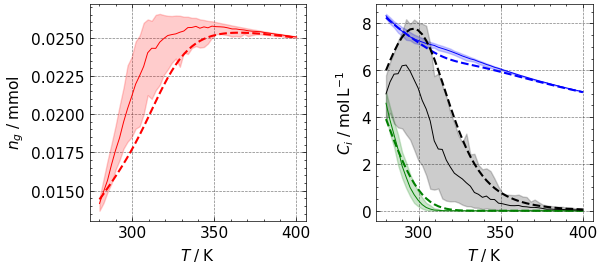

In [77]:
mean_y_hat = y_hatses.mean(axis=1)
CI5 = np.percentile(y_hatses, 5, axis=1)
CI95 = np.percentile(y_hatses, 95, axis=1)

fig = ICIW_Plots.figure(layout="double_column")
axs = ICIW_Plots.make_square_subplots(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    ax_layout=(1, 2),
    h_sep=0.7,
    xlabel=r"$T\;/\;\mathrm{K}$",
    ylabel=[[r"$n_g\;/\;\mathrm{mmol}$", r"$C_i\;/\;\mathrm{mol\,L^{-1}}$"]],
)
axs[0, 0].plot(Ts, mean_y_hat[:, -1, 0], color="red", lw=0.7)
axs[0, 0].plot(Ts, y_trues[:, -1, 0], "--", color="red")
axs[0, 0].fill_between(Ts, CI5[:, -1, 0], CI95[:, -1, 0], color="red", alpha=0.2)
axs[0, 1].plot(Ts, mean_y_hat[:, -1, 1], color="blue", lw=0.7)
axs[0, 1].plot(Ts, y_trues[:, -1, 1], "--", color="blue")
axs[0, 1].fill_between(Ts, CI5[:, -1, 1], CI95[:, -1, 1], color="blue", alpha=0.2)
axs[0, 1].plot(Ts, mean_y_hat[:, -1, 2], color="green", lw=0.7)
axs[0, 1].plot(Ts, y_trues[:, -1, 2], "--", color="green")
axs[0, 1].fill_between(Ts, CI5[:, -1, 2], CI95[:, -1, 2], color="green", alpha=0.2)
axs[0, 1].plot(Ts, mean_y_hat[:, -1, 3], color="black", lw=0.7)
axs[0, 1].plot(Ts, y_trues[:, -1, 3], "--", color="black")
axs[0, 1].fill_between(Ts, CI5[:, -1, 3], CI95[:, -1, 3], color="black", alpha=0.2)

the biggest uncertainty is at 320 K, so we can sample there.

## sample the posterior given the third profile at 320 K

In [78]:
## define the second temperature to investigate
y_obs = np.random.normal(y_true[3, :, :], sigma)[::10, :]  # downsample and add noise
model = bmodel(t_obs, 320, y_obs, prior=posterior_idata)
try:
    posterior_idata = az.from_netcdf("HSA_Cam_A_006_posterior_inf3.nc")
    print("Loaded posterior from file.")
except FileNotFoundError:
    vars_list = list(model.values_to_rvs.keys())[:-1]
    with model:
        posterior_idata = pm.sample(
            step=[pm.DEMetropolisZ(vars_list)],
            draws=10000,
            tune=2000,
            # target_accept=0.9,
            random_seed=23489,
            return_inferencedata=True,
            # nuts_sampler="numpyro",
        )
    posterior_idata.to_netcdf("HSA_Cam_A_006_posterior_inf3.nc")

Loaded posterior from file.


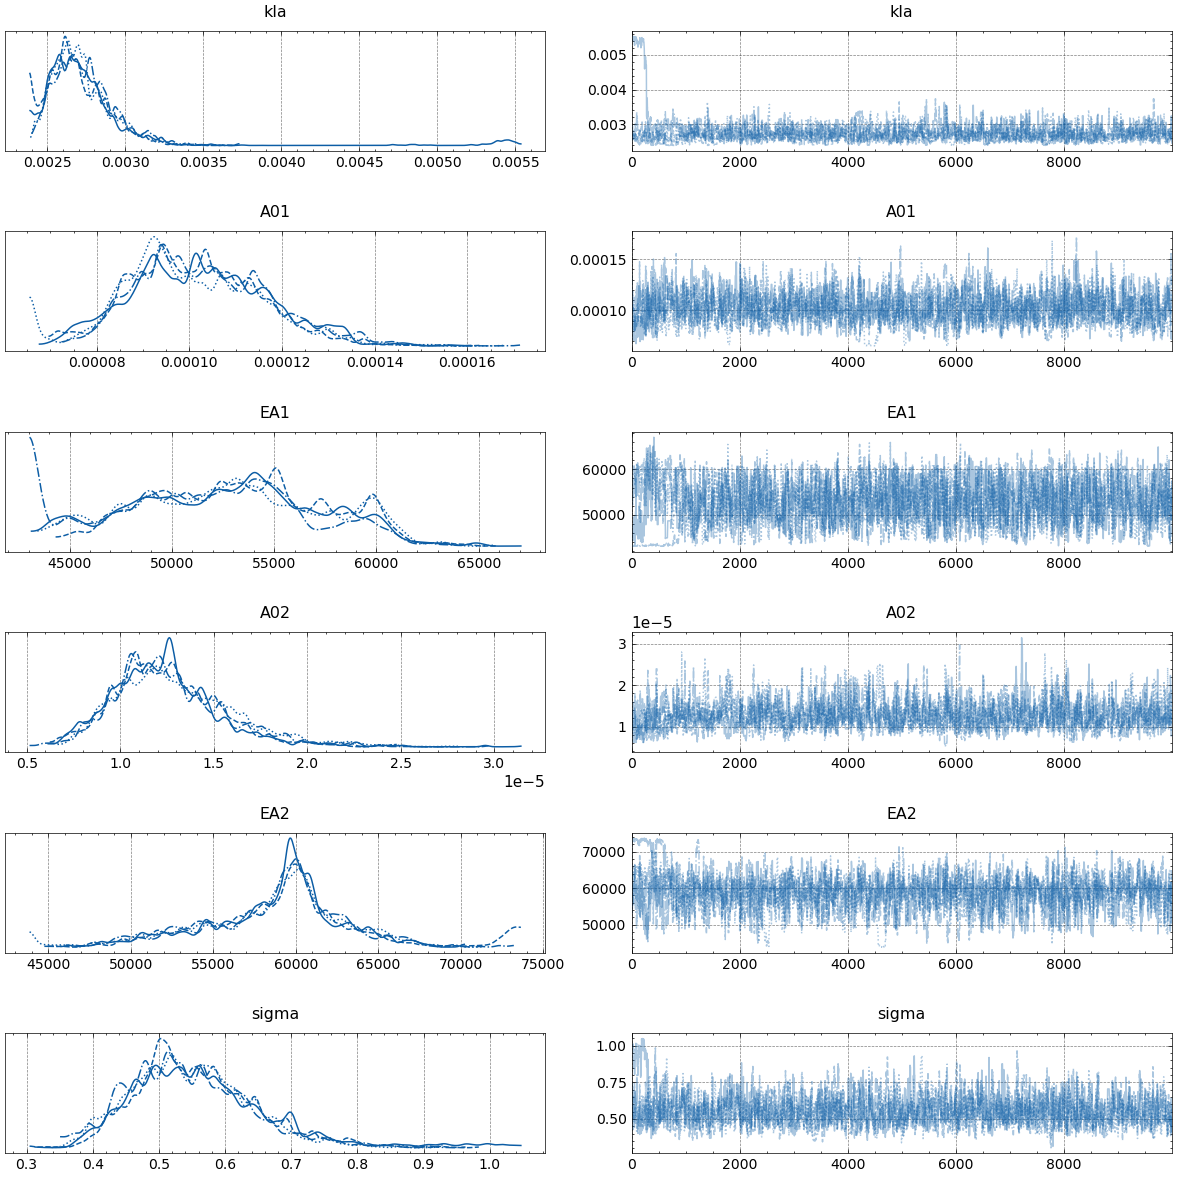

In [79]:
az.plot_trace(
    posterior_idata,
    var_names=[
        "kla",
        "A01",
        "EA1",
        "A02",
        "EA2",
        "sigma",
    ],
)
plt.show()

In [80]:
Ts = np.linspace(280, 400, 50)
y_hatses = []
y_trues = []
for T in Ts:
    y_hats = model_inference(
        posterior_idata,
        y0_true,
        times,
        theta_indep=(10e5, T),
        n_samples=99,
    )
    # print(y_hats.shape)
    y_hatses.append(y_hats)
    y_trues.append(
        odeint(
            Chem.reaction,
            t=times,
            y0=y0_true,
            args=((theta_true[0], T, *theta_true[2:]),),
        )
    )
y_hatses = np.array(y_hatses)
y_trues = np.array(y_trues)

Text(0.5, 0.98, 'Posterior model @ 350 K')

c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\IPython\core\events.py:82: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  func(*args, **kwargs)
c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


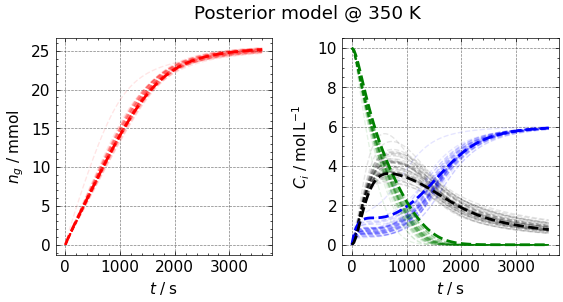

In [85]:
fig = ICIW_Plots.figure(layout="double_column")
axs = ICIW_Plots.make_square_subplots(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    ax_layout=(1, 2),
    h_sep=0.7,
    xlabel=r"$t\;/\;\mathrm{s}$",
    ylabel=[[r"$n_g\;/\;\mathrm{mmol}$", r"$C_i\;/\;\mathrm{mol\,L^{-1}}$"]],
)

plot_inference(
    axs,
    posterior_idata,
    times=times,
    group="posterior",
    num_samples=50,
    theta_indep=(10e5, 350),
    lw=1,
    alpha=0.1,
)
plot_true_data(axs, times, y_true[4, :, :])
plt.suptitle("Posterior model @ 350 K")

<>:27: SyntaxWarning: invalid escape sequence '\m'
<>:27: SyntaxWarning: invalid escape sequence '\m'
C:\Users\hanne\AppData\Local\Temp\ipykernel_4064\2078579502.py:27: SyntaxWarning: invalid escape sequence '\m'
  plt.suptitle("model at $t = 3600 \mathrm{s}$")


Text(0.5, 0.98, 'model at $t = 3600 \\mathrm{s}$')

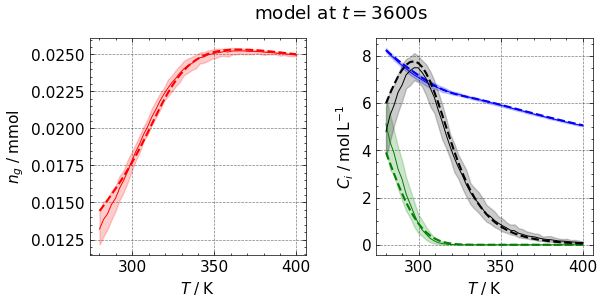

In [87]:
mean_y_hat = y_hatses.mean(axis=1)
CI5 = np.percentile(y_hatses, 5, axis=1)
CI95 = np.percentile(y_hatses, 95, axis=1)

fig = ICIW_Plots.figure(layout="double_column")
axs = ICIW_Plots.make_square_subplots(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    ax_layout=(1, 2),
    h_sep=0.7,
    xlabel=r"$T\;/\;\mathrm{K}$",
    ylabel=[[r"$n_g\;/\;\mathrm{mmol}$", r"$C_i\;/\;\mathrm{mol\,L^{-1}}$"]],
)
axs[0, 0].plot(Ts, mean_y_hat[:, -1, 0], color="red", lw=0.7)
axs[0, 0].plot(Ts, y_trues[:, -1, 0], "--", color="red")
axs[0, 0].fill_between(Ts, CI5[:, -1, 0], CI95[:, -1, 0], color="red", alpha=0.2)
axs[0, 1].plot(Ts, mean_y_hat[:, -1, 1], color="blue", lw=0.7)
axs[0, 1].plot(Ts, y_trues[:, -1, 1], "--", color="blue")
axs[0, 1].fill_between(Ts, CI5[:, -1, 1], CI95[:, -1, 1], color="blue", alpha=0.2)
axs[0, 1].plot(Ts, mean_y_hat[:, -1, 2], color="green", lw=0.7)
axs[0, 1].plot(Ts, y_trues[:, -1, 2], "--", color="green")
axs[0, 1].fill_between(Ts, CI5[:, -1, 2], CI95[:, -1, 2], color="green", alpha=0.2)
axs[0, 1].plot(Ts, mean_y_hat[:, -1, 3], color="black", lw=0.7)
axs[0, 1].plot(Ts, y_trues[:, -1, 3], "--", color="black")
axs[0, 1].fill_between(Ts, CI5[:, -1, 3], CI95[:, -1, 3], color="black", alpha=0.2)

plt.suptitle("model at $t = 3600 \mathrm{s}$")

<>:27: SyntaxWarning: invalid escape sequence '\m'
<>:27: SyntaxWarning: invalid escape sequence '\m'
C:\Users\hanne\AppData\Local\Temp\ipykernel_4064\822489927.py:27: SyntaxWarning: invalid escape sequence '\m'
  plt.suptitle("model at $t = 1800 \mathrm{s}$")


Text(0.5, 0.98, 'model at $t = 1800 \\mathrm{s}$')

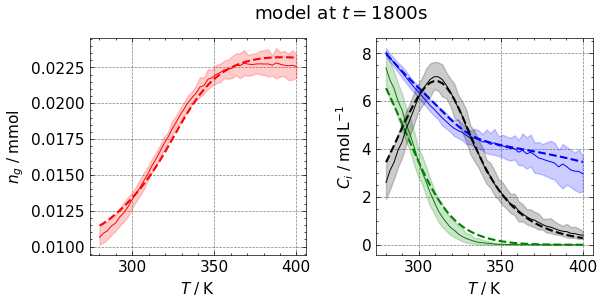

In [88]:
mean_y_hat = y_hatses.mean(axis=1)
CI5 = np.percentile(y_hatses, 5, axis=1)
CI95 = np.percentile(y_hatses, 95, axis=1)

fig = ICIW_Plots.figure(layout="double_column")
axs = ICIW_Plots.make_square_subplots(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    ax_layout=(1, 2),
    h_sep=0.7,
    xlabel=r"$T\;/\;\mathrm{K}$",
    ylabel=[[r"$n_g\;/\;\mathrm{mmol}$", r"$C_i\;/\;\mathrm{mol\,L^{-1}}$"]],
)
axs[0, 0].plot(Ts, mean_y_hat[:, -50, 0], color="red", lw=0.7)
axs[0, 0].plot(Ts, y_trues[:, -50, 0], "--", color="red")
axs[0, 0].fill_between(Ts, CI5[:, -50, 0], CI95[:, -50, 0], color="red", alpha=0.2)
axs[0, 1].plot(Ts, mean_y_hat[:, -50, 1], color="blue", lw=0.7)
axs[0, 1].plot(Ts, y_trues[:, -50, 1], "--", color="blue")
axs[0, 1].fill_between(Ts, CI5[:, -50, 1], CI95[:, -50, 1], color="blue", alpha=0.2)
axs[0, 1].plot(Ts, mean_y_hat[:, -50, 2], color="green", lw=0.7)
axs[0, 1].plot(Ts, y_trues[:, -50, 2], "--", color="green")
axs[0, 1].fill_between(Ts, CI5[:, -50, 2], CI95[:, -50, 2], color="green", alpha=0.2)
axs[0, 1].plot(Ts, mean_y_hat[:, -50, 3], color="black", lw=0.7)
axs[0, 1].plot(Ts, y_trues[:, -50, 3], "--", color="black")
axs[0, 1].fill_between(Ts, CI5[:, -50, 3], CI95[:, -50, 3], color="black", alpha=0.2)

plt.suptitle("model at $t = 1800 \mathrm{s}$")